In [10]:
import sys
from pathlib import Path

project_root = Path.cwd().parents[0]
sys.path.append(str(project_root))

from algorithms.tss_file import TSSFile
from algorithms.wfm_edge import WFM_edge
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

In [13]:
file = 'Tek20260904T180733.tss'
folder = r'Y:\TESTDATA\DP\2026\09\04\2630A000V1\Vd400_Id200_Vg15'
tss = TSSFile(folder, file, source='Local')
channel_labels = tss.channel_labels
print(channel_labels)
time = tss.waveforms['ch1'].time_for_frame()
vg = tss.waveforms['ch1'].values_for_frame(0)
vgi = tss.waveforms['ch8'].values_for_frame(0)
# vd = tss.waveforms['ch3'].values_for_frame(0)
Is = tss.waveforms['ch2'].values_for_frame(0)
ig = tss.waveforms['ch7'].values_for_frame(0)
vblnk = tss.waveforms['ch6'].values_for_frame(0)
vcl = tss.waveforms['ch4'].values_for_frame(0)
flt = tss.waveforms['ch5'].values_for_frame(0)

{'ch1': 'VGO_LS', 'ch2': 'Is', 'ch3': 'Vd', 'ch4': 'Vcl', 'ch5': 'FLT', 'ch6': 'BLK%0A', 'ch7': 'IG', 'ch8': 'VGI%0A'}


Desat blank: 393.57644104725205 ns


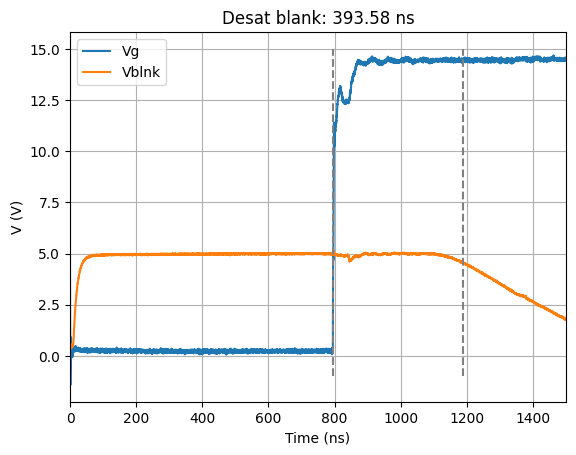

In [15]:
vg_edges = WFM_edge(vg, time, sigma=100)
vblnk_edges = WFM_edge(vblnk, time, sigma=200)
#print(vblnk_edges.falling_edge_number)
#print(vblnk_edges.rising_edge_number)
time1 = vg_edges.get_edge(2, 'rising', 10)['time']
time2 = vblnk_edges.get_edge(2, 'falling', 90)['time']
#print(time2*1e9)
desat_blank = (time2 - time1) * 1e9
print(f'Desat blank: {desat_blank} ns')

plt.plot(time*1e9, vg, label='Vg')
plt.plot(time*1e9, vblnk, label='Vblnk')
plt.xlim([0e3, 1.5e3])
plt.vlines(time1*1e9, -1, 15, color='grey', linestyles='--')
plt.vlines(time2*1e9, -1, 15, color='grey', linestyles='--')
plt.xlabel('Time (ns)')
plt.ylabel('V (V)')
plt.title(f'Desat blank: {desat_blank:.2f} ns')
plt.legend()
plt.grid()
plt.show()

153.93702097748888


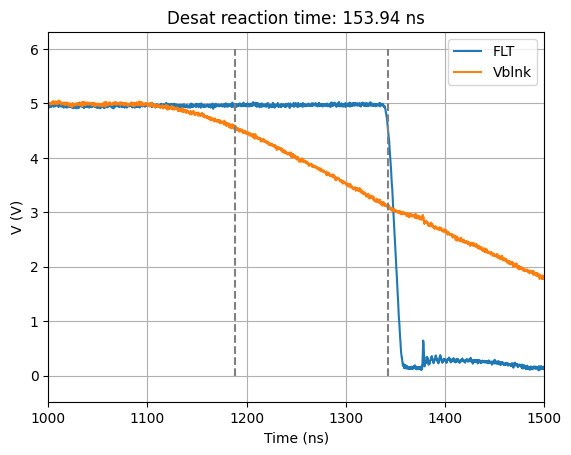

In [16]:
flt_edges = WFM_edge(flt, time, sigma=100)
time2 = vblnk_edges.get_edge(2, 'falling', 90)['time']
time3 = flt_edges.get_edge(2, 'falling', 90)['time']
desat_t_react  = (time3 - time2) * 1e9
print(desat_t_react)

plt.plot(time*1e9, flt, label='FLT')
plt.plot(time*1e9, vblnk, label='Vblnk')
plt.xlim([1e3, 1.5e3])
plt.vlines(time2*1e9, 0, 6, color='grey', linestyles='--')
plt.vlines(time3*1e9, 0, 6, color='grey', linestyles='--')
plt.xlabel('Time (ns)')
plt.ylabel('V (V)')
plt.title(f'Desat reaction time: {desat_t_react:.2f} ns')
plt.legend()
plt.grid()
plt.show()

22.51845076347642


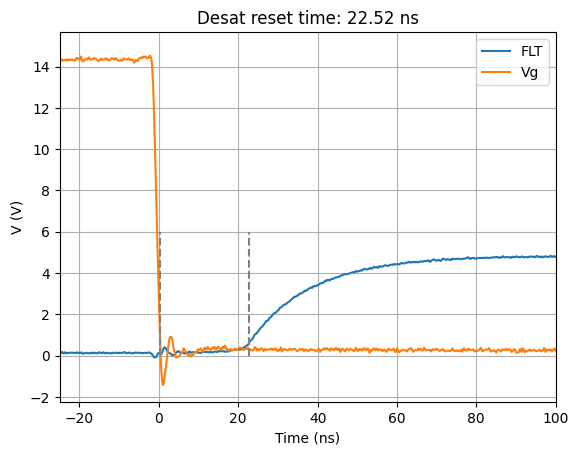

In [17]:
time4 = vg_edges.get_edge(1, 'falling', 10)['time']
time5 = flt_edges.get_edge(1, 'rising', 10)['time']
desat_reset_time  = (time5 - time4) * 1e9
print(desat_reset_time)

plt.plot(time*1e9, flt, label='FLT')
plt.plot(time*1e9, vg, label='Vg')
plt.xlim([-25, 100])
plt.vlines(time4*1e9, 0, 6, color='grey', linestyles='--')
plt.vlines(time5*1e9, 0, 6, color='grey', linestyles='--')
plt.xlabel('Time (ns)')
plt.ylabel('V (V)')
plt.title(f'Desat reset time: {desat_reset_time:.2f} ns')
plt.legend()
plt.grid()
plt.show()

123.11923563611003


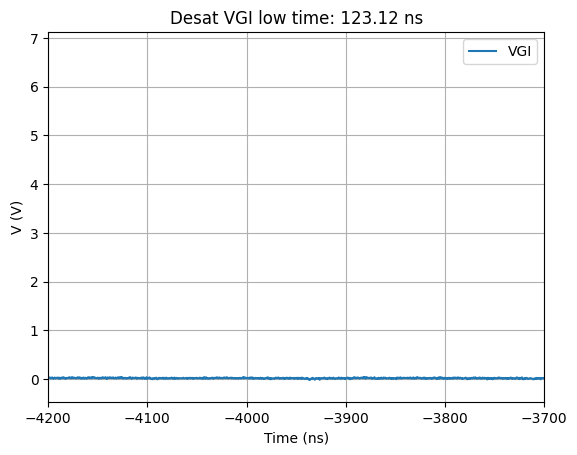

In [18]:
vgi_edges = WFM_edge(vgi, time, sigma=100)
time6 = vgi_edges.get_edge(1, 'falling', 90)['time']
time7 = vgi_edges.get_edge(1, 'falling', 10)['time']
desat_VGI_tlow  = (time7 - time6) * 1e9
print(desat_VGI_tlow)

plt.plot(time*1e9, vgi, label='VGI')
plt.xlim([-4.2e3, -3.7e3])
plt.vlines(time6*1e9, 0, 6, color='grey', linestyles='--')
plt.vlines(time7*1e9, 0, 6, color='grey', linestyles='--')
plt.xlabel('Time (ns)')
plt.ylabel('V (V)')
plt.title(f'Desat VGI low time: {desat_VGI_tlow:.2f} ns')
plt.legend()
plt.grid()
plt.show()

76.74375


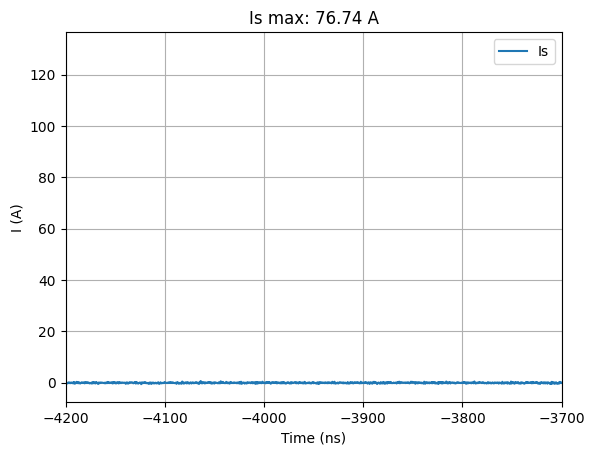

In [19]:
idx1 = vgi_edges.get_edge(1, 'falling', 99)['thresh_idx']
idx2 = vgi_edges.get_edge(1, 'falling', 1)['thresh_idx']
is_max = max(Is[(idx1-(idx2-idx1)):(idx2+(idx2-idx1))])
print(is_max)
idx_is_max = np.where(Is == is_max)[0][0]

plt.plot(time*1e9, Is, label='Is')
plt.xlim([-4.2e3, -3.7e3])
plt.vlines(time[idx_is_max]*1e9, 0, 130, color='grey', linestyles='--')
plt.xlabel('Time (ns)')
plt.ylabel('I (A)')
plt.title(f'Is max: {is_max:.2f} A')
plt.legend()
plt.grid()
plt.show()

55.156250000000014
130.95050000000003


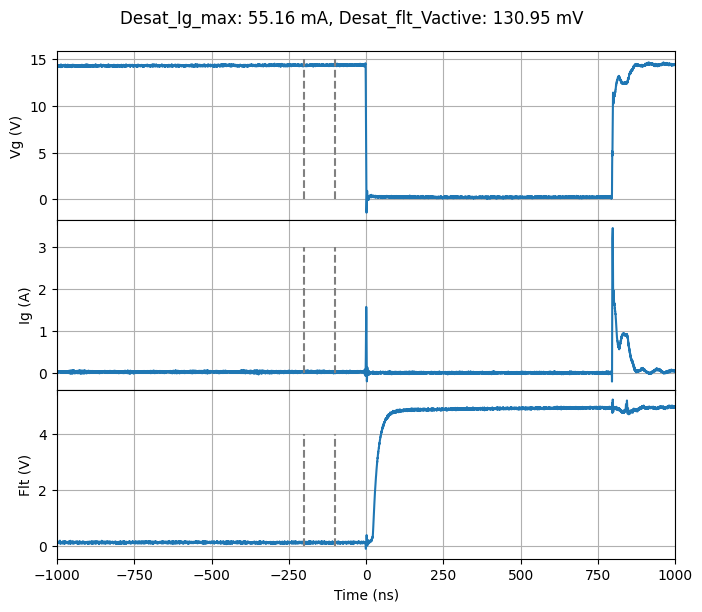

In [20]:
time_inter = time[1] - time[0]
idx4 = vg_edges.get_edge(1, 'falling', 99)['thresh_idx'] - int(0.1e-6/time_inter)
idx3 = np.argmin(np.abs(time - (time[idx4]-0.1e-6)))

desat_Ig_max = max(ig[idx3:idx4])*1e3
print(desat_Ig_max)
desat_flt_Vactive = np.average(flt[idx3:idx4])*1e3
print(desat_flt_Vactive)
fig, axs = plt.subplots(3, 1, sharex=True, figsize=(7, 2*3))
fig.suptitle(f'Desat_Ig_max: {desat_Ig_max:.2f} mA, Desat_flt_Vactive: {desat_flt_Vactive:.2f} mV')
fig.tight_layout()
fig.subplots_adjust(hspace=0)

axs[0].plot(time*1e9, vg)
axs[0].set_ylabel('Vg (V)')
axs[0].set_xlabel('Time (ns)')
axs[0].vlines(time[idx3]*1e9, 0, 15, color='grey', linestyles='--')
axs[0].vlines(time[idx4]*1e9, 0, 15, color='grey', linestyles='--')
axs[0].grid(True)

axs[1].plot(time*1e9, ig)
axs[1].set_ylabel('Ig (A)')
axs[1].vlines(time[idx3]*1e9, 0, 3, color='grey', linestyles='--')
axs[1].vlines(time[idx4]*1e9, 0, 3, color='grey', linestyles='--')
axs[1].grid(True)

axs[2].plot(time*1e9, flt)
axs[2].vlines(time[idx3]*1e9, 0, 4, color='grey', linestyles='--')
axs[2].vlines(time[idx4]*1e9, 0, 4, color='grey', linestyles='--')
axs[2].set_ylabel('Flt (V)')
axs[2].grid(True)

plt.xlabel('Time (ns)')
plt.xlim([-1000, 1000])
plt.show()

7.673697916666666


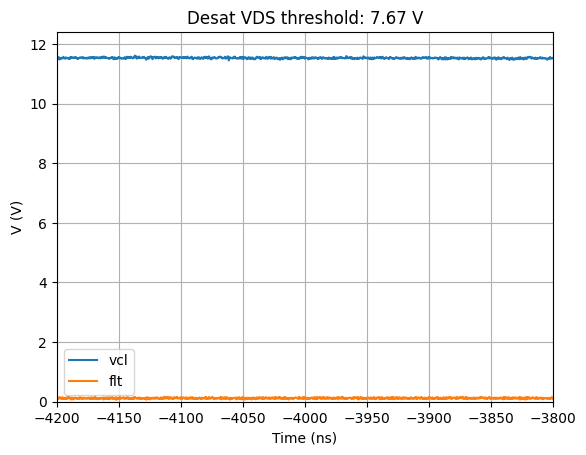

In [21]:
time9 = flt_edges.get_edge(1, 'falling', 10)['time']
time8 = time9 - desat_t_react*1e-9
idx5 = np.argmin(np.abs(time - time8))
desat_VDS_th = np.average(vcl[idx5-3:idx5+3])
print(desat_VDS_th)

plt.plot(time*1e9, vcl, label='vcl')
plt.plot(time*1e9, flt, label='flt')
plt.xlim([-4200, -3800])
plt.ylim([0, 12.4])
plt.vlines(time9*1e9, 0, 12.4, color='grey', linestyles='--')
plt.vlines(time[idx5]*1e9, 0, 12.4, color='grey', linestyles='--')
plt.xlabel('Time (ns)')
plt.ylabel('V (V)')
plt.title(f'Desat VDS threshold: {desat_VDS_th:.2f} V')
plt.legend()
plt.grid()
plt.show()